# 3. Entity extraction (organizations and technologies)

| | |
|---|---|
| **Reads** | def_news_AI_clean_topics.parquet |
| **Writes** | entity_extraction.pkl, df_filtered_entities.parquet |
| **Next** | 04_sentiment_analysis.ipynb |

**Paths:** the first code cell defines `DATA_DIR`: a Google Drive folder when running in Colab, `<repo>/data/` when running locally (start Jupyter from the `notebooks/` folder).

## 1. Packages

In [1]:
# Basic imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import spacy
import pickle
# Enity extraction
import torch
from transformers import pipeline
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForTokenClassification, pipeline
from transformers.pipelines.pt_utils import KeyDataset
from collections import Counter

In [ ]:
# ---- Environment setup: works in Google Colab and locally ----
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    # Google Drive folder that holds the intermediate files (change it if yours is different)
    DATA_DIR = "/content/drive/MyDrive/Colab Notebooks/Final Project NLP"
except ImportError:
    # Local run: intermediate files live in <repo>/data/ (start Jupyter from notebooks/)
    DATA_DIR = str(Path.cwd().parent / "data")
Path(DATA_DIR).mkdir(parents=True, exist_ok=True)
print("DATA_DIR =", DATA_DIR)


## 2. Read data

In [3]:
df_news_AI_clean_topics = pd.read_parquet(f'{DATA_DIR}/def_news_AI_clean_topics.parquet', engine='pyarrow')

In [4]:
display(df_news_AI_clean_topics.head(3))

,url,date,title,text,year,month,text_word_count,title_word_count,clean_title,clean_text,title_word_clean_count,text_word_clean_count,title_text_clean,title_text_clean_count,semantic_score,Topic_Number,Topic_Name,Probability
0,https://blockworks.co/price/bad,2025-06-23,"Bad Idea AI Price (BAD), Market Cap, Price Tod...","Bad Idea AI Price (BAD), Market Cap, Price Tod...",2025,6,483,14,"Bad Idea AI Price (BAD), Market Cap, Price Tod...",Open menuBrandsnewsletterspodcastseventsroundt...,12,470,"Bad Idea AI Price (BAD), Market Cap, Price Tod...",482,0.205120,9,Cryptocurrency & Financial Trading,0.995980
1,https://boingboing.net/2024/07/01/this-ai-vide...,2024-07-01,This AI video of gymnastics might be the freak...,\n\nThis AI video of gymnastics might be the f...,2024,7,812,15,This AI video of gymnastics might be the freak...,"\nJennifer Sandlin\n5:13 am Mon\nJul 1, 2024\n...",12,724,This AI video of gymnastics might be the freak...,736,0.282888,3,Digital Media & Entertainment,0.974883
2,https://boingboing.net/2024/09/18/if-using-ai-...,2024-09-22,"If using AI feels like a chore, try this - Boi...","\n\nIf using AI feels like a chore, try this -...",2024,9,884,12,"If using AI feels like a chore, try this","\nBoing Boing's Shop\n8:00 am Wed\nSep 18, 202...",9,802,"If using AI feels like a chore, try this \nBoi...",811,0.378478,3,Digital Media & Entertainment,0.453399


In [5]:
print('Initial dataframe shape :', df_news_AI_clean_topics.shape)
print('Columns in the dataframe :', df_news_AI_clean_topics.columns)

Initial dataframe shape : (186029, 18)
Columns in the dataframe : Index(['url', 'date', 'title', 'text', 'year', 'month', 'text_word_count',
       'title_word_count', 'clean_title', 'clean_text',
       'title_word_clean_count', 'text_word_clean_count', 'title_text_clean',
       'title_text_clean_count', 'semantic_score', 'Topic_Number',
       'Topic_Name', 'Probability'],
      dtype='object')


In [6]:
display(df_news_AI_clean_topics.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186029 entries, 0 to 186028
Data columns (total 18 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   url                     186029 non-null  object        
 1   date                    186029 non-null  datetime64[ns]
 2   title                   186029 non-null  object        
 3   text                    186029 non-null  object        
 4   year                    186029 non-null  int32         
 5   month                   186029 non-null  int32         
 6   text_word_count         186029 non-null  int64         
 7   title_word_count        186029 non-null  int64         
 8   clean_title             186029 non-null  object        
 9   clean_text              186029 non-null  object        
 10  title_word_clean_count  186029 non-null  int64         
 11  text_word_clean_count   186029 non-null  int64         
 12  title_text_clean        186029

None

In [7]:
# 1. Check for GPU (highly recommended for 50k articles)
device = 0 if torch.cuda.is_available() else -1
print(f"Using device: {'GPU' if device == 0 else 'CPU'}")

Using device: GPU


In [8]:
# Do a sample of 10% of the data to understand the process
#df_news_AI_clean_topics = df_news_AI_clean_topics.sample(frac=0.05, random_state=97)

In [9]:
# Check missing values
print('Number of missing values:', df_news_AI_clean_topics['title_text_clean'].isna().sum())
print(len(df_news_AI_clean_topics))

Number of missing values: 0
186029


## 3. Enity extraction

In [10]:
# bert-base-NER selected model
# bert-base-NER is a fine-tuned BERT model that is ready to use for Named Entity Recognition and achieves state-of-the-art performance for the NER task.
# It has been trained to recognize four types of entities: location (LOC), organizations (ORG), person (PER) and Miscellaneous (MISC).

# Model 1: "dslim/bert-base-NER"
# Model 2: "djagatiya/ner-bert-base-cased-ontonotesv5-englishv4"


In [11]:
%%time
model_name = "djagatiya/ner-bert-base-cased-ontonotesv5-englishv4"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForTokenClassification.from_pretrained(model_name)
# Run the (slow) NER inference only if no cached result exists yet
run = not Path(f"{DATA_DIR}/entity_extraction.pkl").exists()
if run:
  #aggregation_strategy="simple" automatically groups "B-ORG" and "I-ORG" into one "ORG" word.
  ner_pipe = pipeline(
      "ner",
      model=model,
      aggregation_strategy="simple",
      tokenizer=tokenizer,
      device=device,
      batch_size=128
  )

  # 3. Transform pandas dataframe into Hugging Face Dataset
  hf_dataset_entity = Dataset.from_pandas(df_news_AI_clean_topics)

  # 4. Run Batch Inference
  print("Starting extraction... This might take a while depending on your hardware.")

  extracted_results = []
  for output in ner_pipe(KeyDataset(hf_dataset_entity, "title_text_clean")):
      extracted_results.append(output)
  print("Extraction complete!")

  # save result
  file_path = f"{DATA_DIR}/entity_extraction.pkl"
  with open(file_path, "wb") as f:
    pickle.dump(extracted_results, f)
  print(f"Successfully saved to {file_path}")
# load previuos result
else:
  file_path = f"{DATA_DIR}/entity_extraction.pkl"
  with open(file_path, "rb") as f:
    extracted_results = pickle.load(f)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

CPU times: user 5.49 s, sys: 1.68 s, total: 7.17 s
Wall time: 8.8 s


In [12]:
# Save coherence_scores
#file_path = f"{DATA_DIR}/entity_extraction.pkl"
#with open(file_path, "wb") as f:
#    pickle.dump(extracted_results, f)
#print(f"Successfully saved to {file_path}")

In [13]:
# 1. Define the specific labels you want to keep
target_labels = ['ORG', 'PRODUCT']
filtered_entities = []

# 2. Filter the entities list
# We check if the 'entity_group' of each item matches our target labels
for i in range(0, len(extracted_results)):
  filtered_entity = [ent for ent in extracted_results[i] if ent['entity_group'] in target_labels]
  filtered_entities.append(filtered_entity)

In [14]:
# Clean format to extarct in document level the word and entity
dict_filtered_entities = {'index_doc':[], 'word':[], 'entity':[],'frenqency':[]}

# Iterate
for i in range(0, len(filtered_entities)):
  current_doc = filtered_entities[i]
  dict_filtered_entities['index_doc'].append(i)

  # create list words and entity_group
  list_words = []
  list_entities = []
  for ent in current_doc:
    if(len(ent['word'])>1):
      list_words.append(ent['word'])
      list_entities.append(ent['entity_group'])

  # Calculate frequency
  word_counts = Counter(list_words)
  frenqency_words = list(word_counts.values())

  # Keep only unique words and entity
  seen = set()
  unique_words = []
  unique_entities = []
  for w, e in zip(list_words, list_entities):
    if w not in seen:
        unique_words.append(w)
        unique_entities.append(e)
        seen.add(w)

  # Add to a dataframe
  dict_filtered_entities['word'].append(unique_words)
  dict_filtered_entities['entity'].append(unique_entities)
  dict_filtered_entities['frenqency'].append(frenqency_words)


# Transfrom dictonary into a dataframe
df_filtered_entities = pd.DataFrame(dict_filtered_entities)
display(df_filtered_entities.head(10))


,index_doc,word,entity,frenqency
0,0,"[##B, ##works Research, BA]","[ORG, ORG, ORG]","[1, 1, 1]"
1,1,"[Werner, Dream Machine]","[ORG, PRODUCT]","[1, 1]"
2,2,"[this Boing Boing ' s Shop, Cha, GPT - 4, Goog...","[ORG, ORG, PRODUCT, ORG, PRODUCT, ORG, PRODUCT...","[1, 1, 2, 2, 1, 1, 1, 1, 1]"
3,3,"[Fund, de China, China, Baidu]","[ORG, ORG, ORG, ORG]","[1, 1, 1, 1]"
4,4,"[Microsoft, ##vidia, Empower Develo, Windows A...","[ORG, ORG, ORG, PRODUCT, PRODUCT, PRODUCT, ORG...","[8, 3, 1, 5, 1, 1, 3, 1, 1, 1, 1, 1, 1, 1, 1, ..."
5,5,"[Google, Open, ##S, ##nce, Bar, Gemini, ##I, G...","[ORG, ORG, ORG, ORG, PRODUCT, ORG, ORG, ORG, O...","[6, 4, 1, 1, 5, 7, 2, 1, 1, 1]"
6,6,"[Zoom Expands, Companion, ##ccelerator, Zoom V...","[PRODUCT, PRODUCT, PRODUCT, ORG, PRODUCT, PROD...","[1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, ..."
7,7,[Industry],[ORG],[1]
8,8,[],[],[]
9,9,"[Rob, AG, ##modo, Re, ##uters, Big Tech, OpenA...","[PRODUCT, ORG, ORG, ORG, ORG, ORG, ORG, ORG, O...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]"


In [15]:
# Export consolidate parquet
file_path = f"{DATA_DIR}/df_filtered_entities.parquet"
df_filtered_entities.to_parquet(file_path, engine='auto')

### 3.1 Top Enity General

In [16]:
# Top 20 most common entities
df_exploded = df_filtered_entities.explode(['word', 'entity', 'frenqency'])

# 2. Ensure the frequency column is treated as numeric integers
df_exploded['frenqency'] = pd.to_numeric(df_exploded['frenqency'])

# 3. Group by 'word' and 'entity', sum the frequencies
frenq_entities = (df_exploded
                   .groupby(['word', 'entity'], as_index=False)['frenqency']
                   .sum()
                   .sort_values(by='frenqency', ascending=False))

# 4. Reset the index for a clean output
frenq_entities = frenq_entities.reset_index(drop=True)
#total
total = frenq_entities['frenqency'].sum()
frenq_entities['percentage'] = frenq_entities['frenqency'] / total * 100

display(frenq_entities)

,word,entity,frenqency,percentage
0,Google,ORG,53603.0,2.298477
1,Microsoft,ORG,51985.0,2.229098
2,OpenAI,ORG,50664.0,2.172454
3,AI,ORG,38622.0,1.656098
4,Cha,ORG,35735.0,1.532304
...,...,...,...,...
236313,E + D (,ORG,1.0,0.000043
236314,E - 208,PRODUCT,1.0,0.000043
236315,E - 7,PRODUCT,1.0,0.000043
236316,E - A,PRODUCT,1.0,0.000043


,word,entity,frenqency
0,Google,ORG,53603.0
1,Microsoft,ORG,51985.0
2,OpenAI,ORG,50664.0
3,AI,ORG,38622.0
4,Apple,ORG,26393.0
5,Open,ORG,25089.0
6,PR,ORG,24688.0
7,Amazon,ORG,15926.0
8,Nvidia,ORG,15313.0
9,PRNewswire,ORG,12920.0


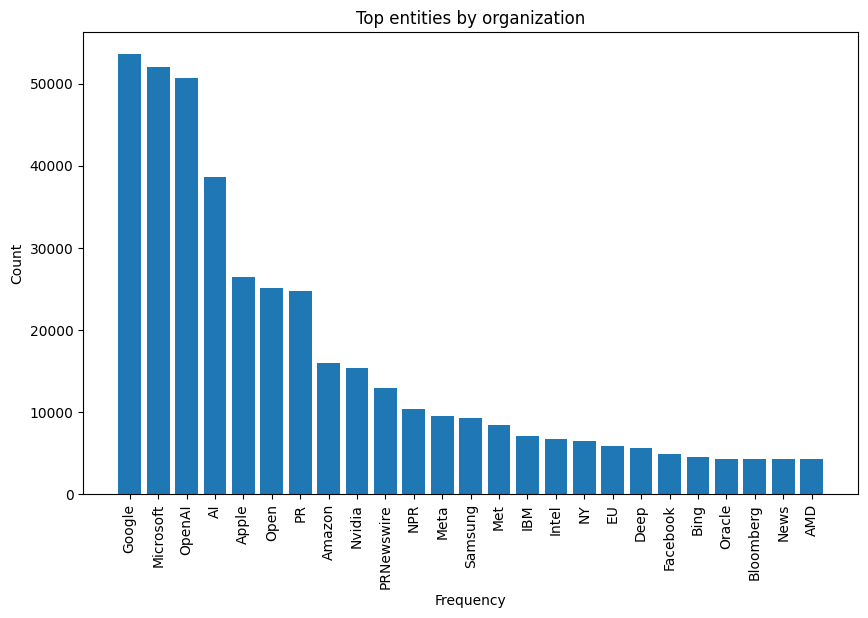

In [17]:
# Filter only ORG
df_aux = frenq_entities[frenq_entities['entity']=='ORG'].copy()
df_aux['word'] = df_aux['word'].str.replace('##vidia', 'Nvidia')
df_aux = df_aux.groupby(['word','entity'])['frenqency'].sum().reset_index()
df_aux = df_aux.sort_values(by='frenqency', ascending=False)

# Remove noise entities
df_aux = df_aux[df_aux['word']!='##I']
df_aux = df_aux[df_aux['word']!='ME']
df_aux = df_aux[df_aux['word']!='Re']
df_aux = df_aux[df_aux['word']!='An']
df_aux = df_aux[df_aux['word']!='PRNews']
df_aux = df_aux[df_aux['word']!='In']
df_aux = df_aux[df_aux['word']!='Cha']
df_aux.reset_index(drop=True, inplace=True)


df_aux = df_aux.head(25)
display(df_aux)

# bar plot
plt.figure(figsize=(10, 6))
plt.bar(df_aux['word'], df_aux['frenqency'])
plt.title("Top entities by organization")
plt.xlabel("Frequency")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

,word,entity,frenqency
12465,AI,PRODUCT,6670.0
22320,Gemini,PRODUCT,6170.0
16912,Cha,PRODUCT,4841.0
21615,GP,PRODUCT,3937.0
21637,GPT - 4,PRODUCT,2602.0
39499,iPhone,PRODUCT,1355.0
21726,GPU,PRODUCT,1020.0
38231,Windows 11,PRODUCT,961.0
15849,Bing,PRODUCT,892.0
13299,AII,PRODUCT,880.0


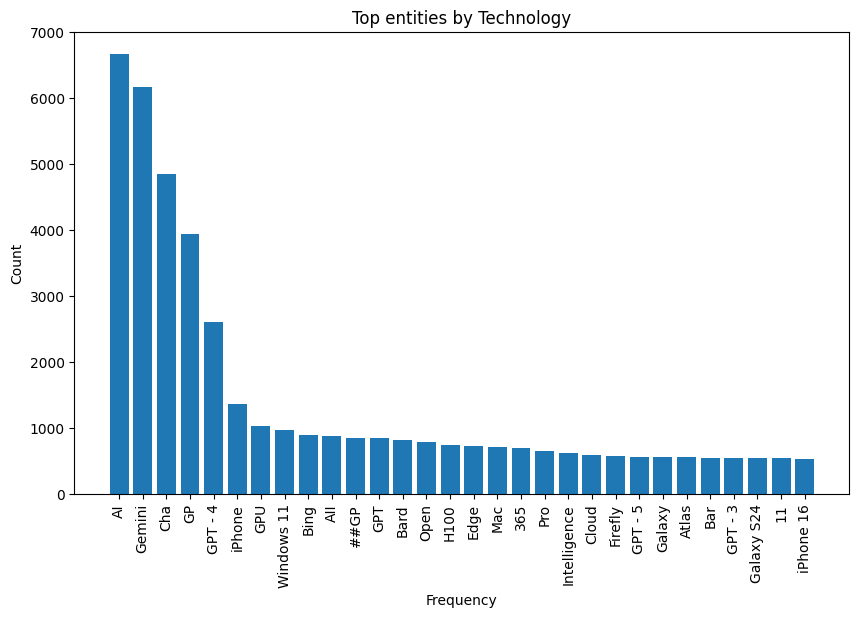

In [18]:
# Filter only product
df_aux = frenq_entities[frenq_entities['entity']=='PRODUCT'].copy()

df_aux['word'] = df_aux['word'].str.replace('##A', 'AI')
df_aux = df_aux.groupby(['word','entity'])['frenqency'].sum().reset_index()
df_aux = df_aux.sort_values(by='frenqency', ascending=False)


# Remove noise entities
df_aux = df_aux[df_aux['word']!='##I']
df_aux = df_aux[df_aux['word']!='##t']
df_aux = df_aux[df_aux['word']!='the']
df_aux = df_aux[df_aux['word']!='##lot']
df_aux = df_aux[df_aux['word']!='##lot']
df_aux = df_aux[df_aux['word']!='##3']
df_aux = df_aux[df_aux['word']!='##T']
df_aux = df_aux[df_aux['word']!='Pi']
df_aux = df_aux[df_aux['word']!='In']
df_aux = df_aux[df_aux['word']!='##2']
df_aux = df_aux[df_aux['word']!='##VI']
df_aux = df_aux[df_aux['word']!='Co']
df_aux = df_aux[df_aux['word']!='So']
df_aux = df_aux[df_aux['word']!='Re']

df_aux = df_aux.head(30)
display(df_aux)

plt.figure(figsize=(10, 6))
plt.bar(df_aux['word'], df_aux['frenqency'])
plt.title("Top entities by Technology")
plt.xlabel("Frequency")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

### 3.2 Enity by topic modeling

In [19]:
# Merge both dataframe
initial_rows = len(df_news_AI_clean_topics)
df_news_AI_entity = df_news_AI_clean_topics.copy()
df_news_AI_entity['index'] = df_news_AI_clean_topics.index
df_news_AI_entity = pd.merge(df_news_AI_entity, df_filtered_entities, left_on='index', right_on='index_doc', how='inner')
final_rows = len(df_news_AI_entity)
print(f'Initial rows: {initial_rows}, Final rows: {final_rows}')

Initial rows: 186029, Final rows: 186029


Topic: 1


,word,entity,frenqency
8548,Google,ORG,17900.0
4611,Apple,ORG,7031.0
14304,Samsung,ORG,5636.0
11543,Microsoft,ORG,5051.0
12750,OpenAI,ORG,2635.0
8243,Galaxy,ORG,2257.0
17375,Windows,ORG,1762.0
8315,Gemini,ORG,1248.0


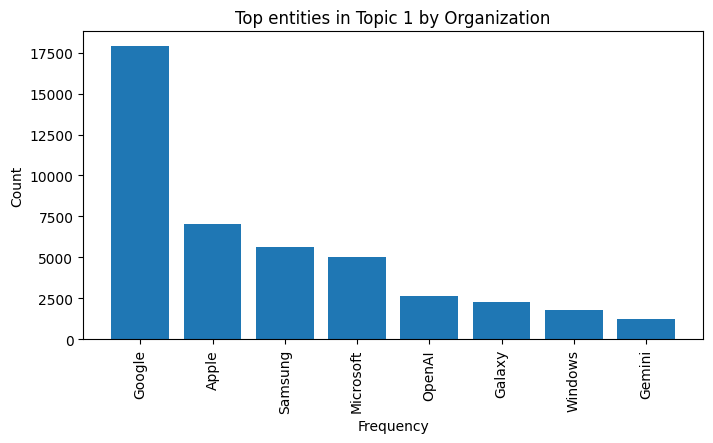

,word,entity,frenqency
7336,Gemini,PRODUCT,3784.0
4219,AI,PRODUCT,1124.0
12913,Windows 11,PRODUCT,762.0
13434,iPhone,PRODUCT,647.0
5119,Bard,PRODUCT,598.0
7144,Galaxy S24,PRODUCT,498.0
7002,Galaxy,PRODUCT,480.0
11176,S24,PRODUCT,379.0


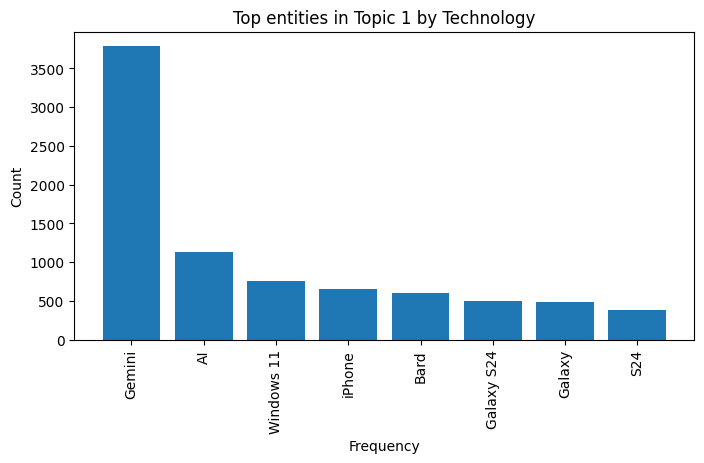

Topic: 2


,word,entity,frenqency
12152,OpenAI,ORG,6408.0
8419,Google,ORG,5869.0
11017,Microsoft,ORG,4197.0
3567,AI,ORG,2155.0
11412,NPR,ORG,1358.0
4453,Associated Press,ORG,1166.0
6265,Congress,ORG,1116.0
14786,The Associated Press,ORG,1039.0


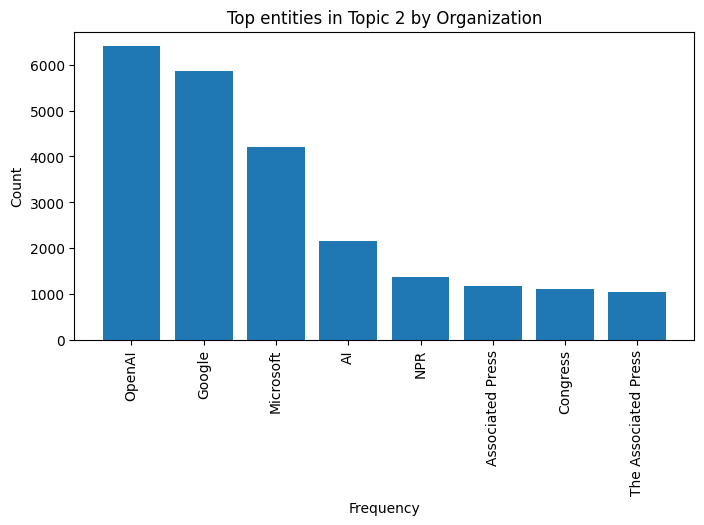

,word,entity,frenqency
999,GPT - 4,PRODUCT,273.0
590,AI,PRODUCT,235.0
1026,Gemini,PRODUCT,211.0
951,Ernie Bot,PRODUCT,211.0
717,Bing,PRODUCT,202.0
1184,La,PRODUCT,153.0
995,GP,PRODUCT,106.0
1072,Grok 3,PRODUCT,90.0


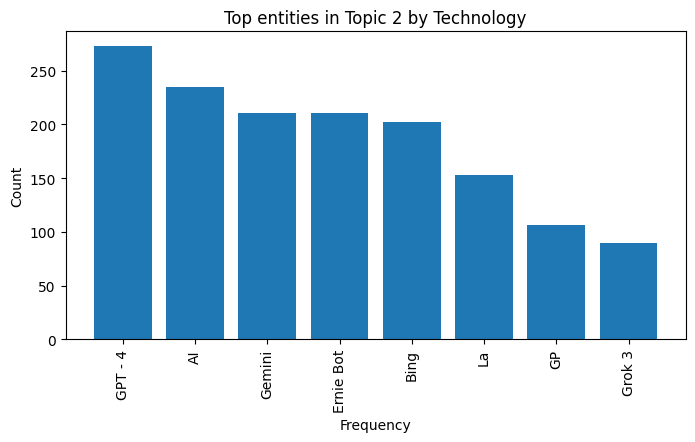

Topic: 3


,word,entity,frenqency
20452,Nvidia,ORG,11337.0
18959,Microsoft,ORG,10957.0
20798,OpenAI,ORG,10434.0
14860,Google,ORG,6956.0
8621,Apple,ORG,5823.0
6947,AI,ORG,5474.0
8313,Amazon,ORG,4892.0
16502,Intel,ORG,3658.0


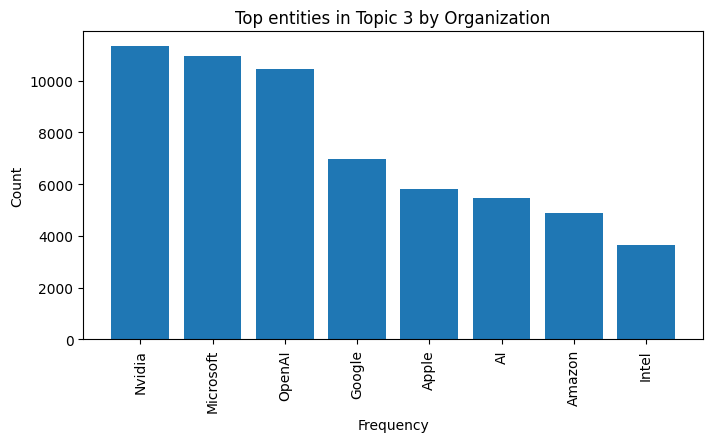

,word,entity,frenqency
4255,GP,PRODUCT,1557.0
2499,AI,PRODUCT,920.0
4293,GPU,PRODUCT,660.0
4580,H100,PRODUCT,581.0
4384,Gemini,PRODUCT,463.0
4263,GPT - 4,PRODUCT,412.0
4596,H20,PRODUCT,318.0
5948,OpenAI,PRODUCT,243.0


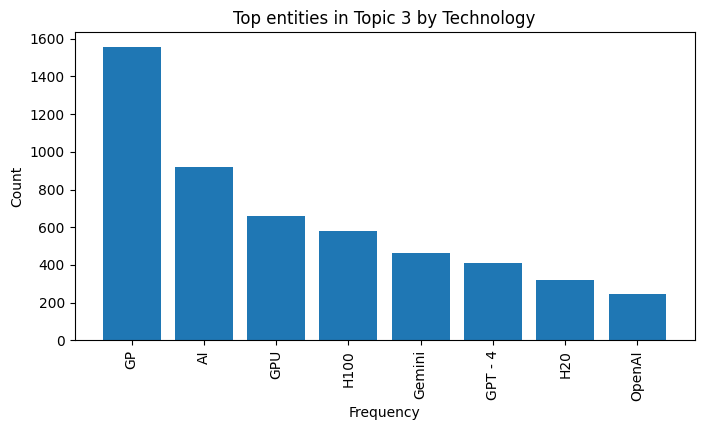

Topic: 4


,word,entity,frenqency
19763,OpenAI,ORG,3309.0
18059,Microsoft,ORG,3150.0
13707,Google,ORG,2883.0
6187,AI,ORG,2128.0
7346,Amazon,ORG,2079.0
7587,Apple,ORG,1947.0
17940,Met,ORG,1602.0
17943,Meta,ORG,1122.0


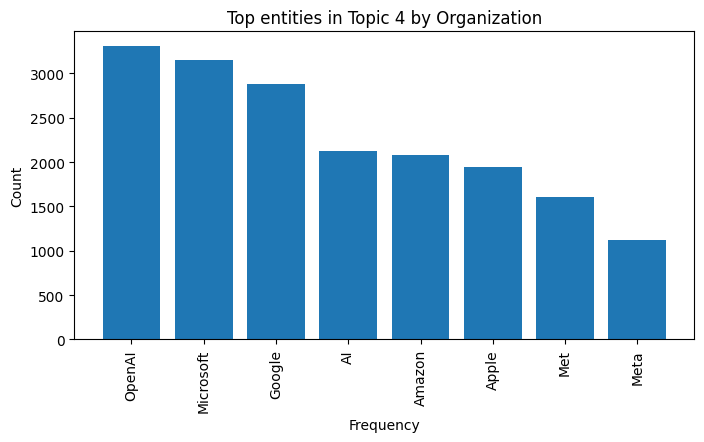

,word,entity,frenqency
2373,AI,PRODUCT,395.0
4137,Gemini,PRODUCT,311.0
2966,Bing,PRODUCT,261.0
2699,Alex,PRODUCT,219.0
3982,GP,PRODUCT,143.0
3685,Edge,PRODUCT,137.0
4225,Golf,PRODUCT,102.0
7152,Windows 11,PRODUCT,93.0


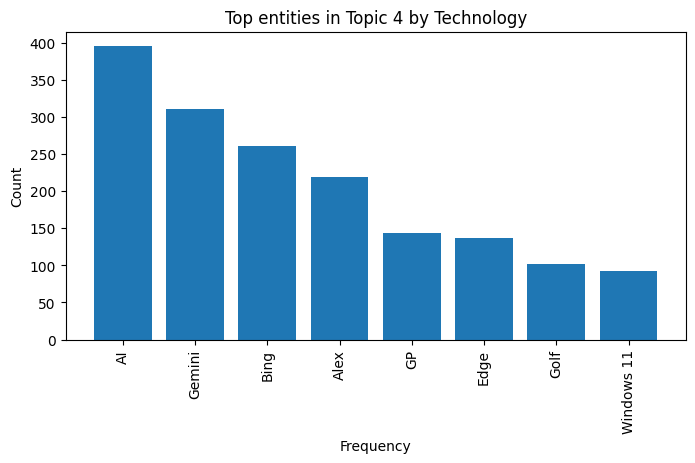

Topic: 5


,word,entity,frenqency
15943,NPR,ORG,8140.0
17056,OpenAI,ORG,5475.0
15240,Microsoft,ORG,4655.0
11358,Google,ORG,2376.0
5646,Amazon,ORG,2060.0
4918,AI,ORG,1677.0
15873,NFL,ORG,1451.0
5849,Apple,ORG,1311.0


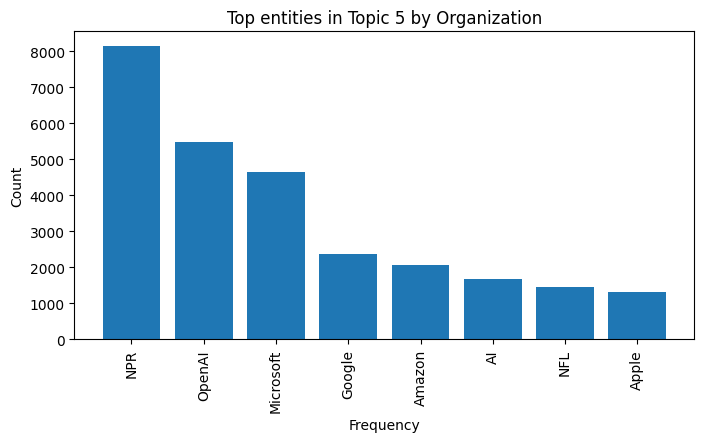

,word,entity,frenqency
986,Gemini,PRODUCT,201.0
564,AI,PRODUCT,126.0
527,365,PRODUCT,81.0
311,##look,PRODUCT,78.0
955,GPT - 4,PRODUCT,77.0
683,Bing,PRODUCT,74.0
1274,OpenAI,PRODUCT,66.0
950,GP,PRODUCT,63.0


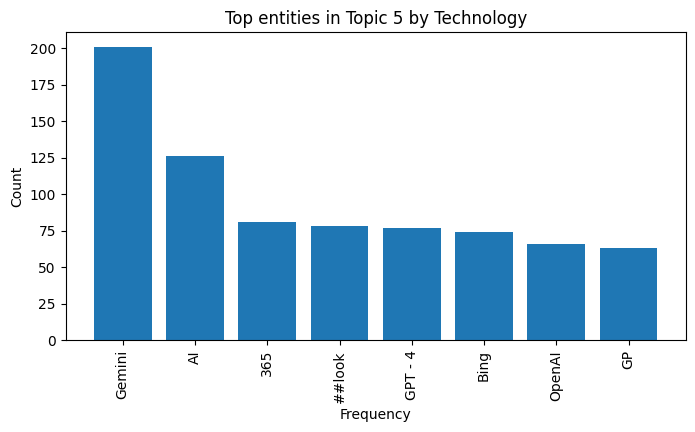

Topic: 6


,word,entity,frenqency
13027,OpenAI,ORG,16207.0
9088,Google,ORG,6986.0
11817,Microsoft,ORG,6213.0
4031,AI,ORG,2378.0
4439,Adobe,ORG,2359.0
11737,Meta,ORG,1886.0
11735,Met,ORG,1866.0
4775,An,ORG,1686.0


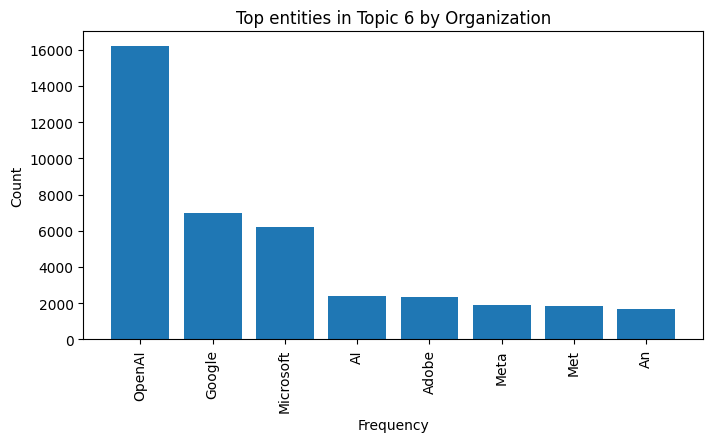

,word,entity,frenqency
3961,GPT - 4,PRODUCT,1228.0
2334,AI,PRODUCT,1161.0
4071,Gemini,PRODUCT,843.0
3946,GP,PRODUCT,798.0
3823,Firefly,PRODUCT,492.0
3948,GPT,PRODUCT,357.0
5375,OpenAI,PRODUCT,339.0
3953,GPT - 3,PRODUCT,282.0


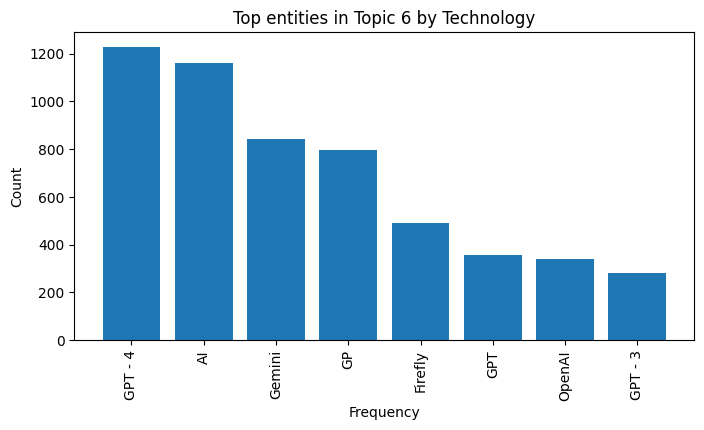

Topic: 7


,word,entity,frenqency
18254,OpenAI,ORG,20091.0
7320,Apple,ORG,7533.0
16741,Microsoft,ORG,6991.0
6095,AI,ORG,5121.0
13237,Google,ORG,3450.0
18010,Nvidia,ORG,2401.0
16616,Meta,ORG,1565.0
462,##I,ORG,1556.0


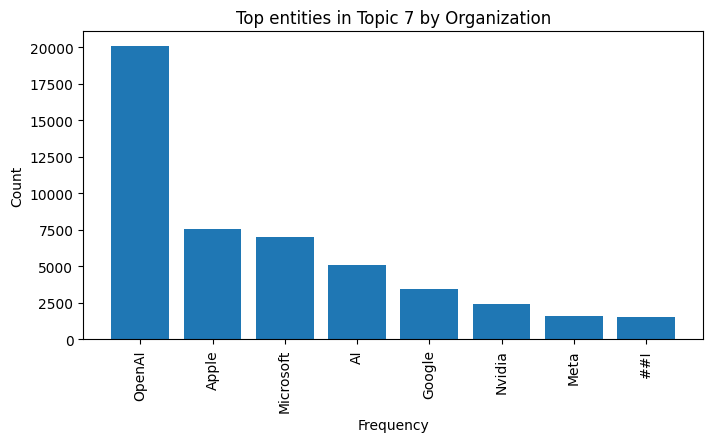

,word,entity,frenqency
2350,iPhone,PRODUCT,450.0
887,AI,PRODUCT,399.0
1371,GPT - 4,PRODUCT,207.0
1365,GP,PRODUCT,147.0
1559,Intelligence,PRODUCT,130.0
1424,Gemini,PRODUCT,129.0
1832,Op,PRODUCT,122.0
2358,iPhone 16,PRODUCT,119.0


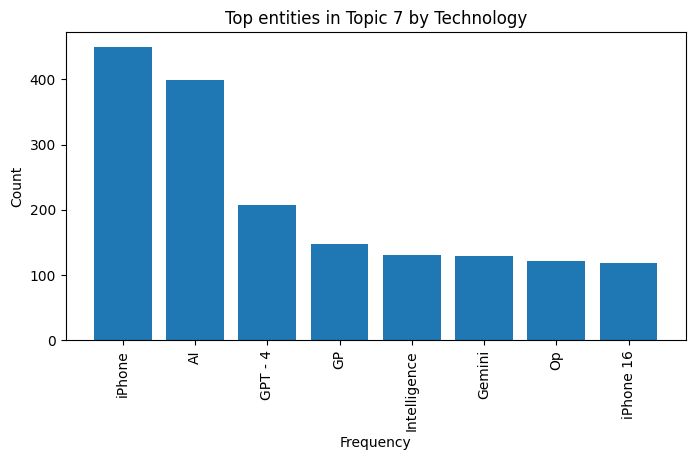

Topic: 8


,word,entity,frenqency
8749,AI,ORG,10105.0
30836,OpenAI,ORG,9132.0
28006,Microsoft,ORG,6156.0
21396,Google,ORG,3678.0
18296,EU,ORG,3462.0
31309,PRNewswire,ORG,1807.0
22999,IBM,ORG,1382.0
15902,Congress,ORG,1308.0


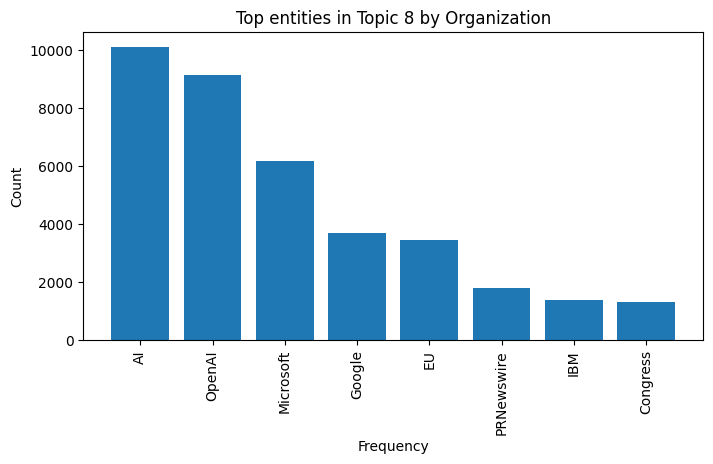

,word,entity,frenqency
827,AI,PRODUCT,271.0
1434,GPT - 4,PRODUCT,71.0
1999,Python,PRODUCT,67.0
1466,Gemini,PRODUCT,63.0
1428,GP,PRODUCT,59.0
1599,Insights,PRODUCT,55.0
868,AI Symptom Checker,PRODUCT,54.0
114,##M,PRODUCT,36.0


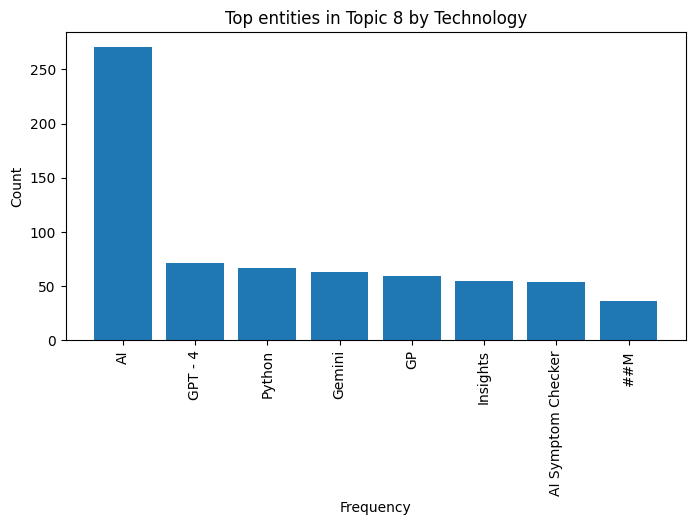

Topic: 9


,word,entity,frenqency
33440,PRNewswire,ORG,9137.0
10477,AI,ORG,8499.0
33320,PRNews,ORG,4903.0
30147,Microsoft,ORG,4221.0
23689,Google,ORG,3059.0
25299,IBM,ORG,2118.0
23714,Google Cloud,ORG,2034.0
32905,Oracle,ORG,1952.0


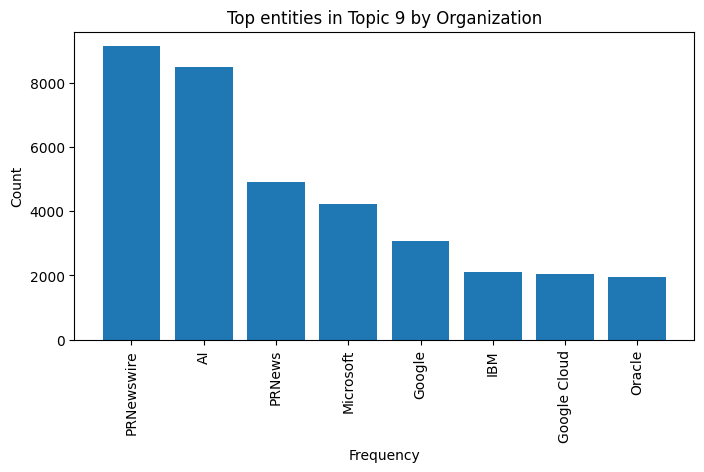

,word,entity,frenqency
3706,AI,PRODUCT,1897.0
6416,GP,PRODUCT,758.0
5113,Cloud,PRODUCT,382.0
7176,Jetson,PRODUCT,376.0
6518,Gene,PRODUCT,265.0
6430,GPU,PRODUCT,244.0
8278,Nvidia,PRODUCT,217.0
7380,Landing,PRODUCT,214.0


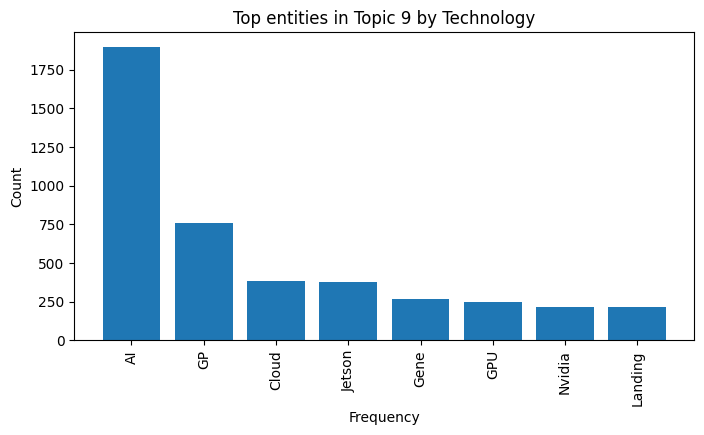

Topic: 10


,word,entity,frenqency
15172,ME,ORG,3139.0
5032,AI,ORG,2708.0
11237,Fiat,ORG,823.0
7470,Bit,ORG,679.0
11239,Fiat Cal,ORG,602.0
17124,OpenAI,ORG,531.0
17304,Oz,ORG,523.0
16258,NAS,ORG,515.0


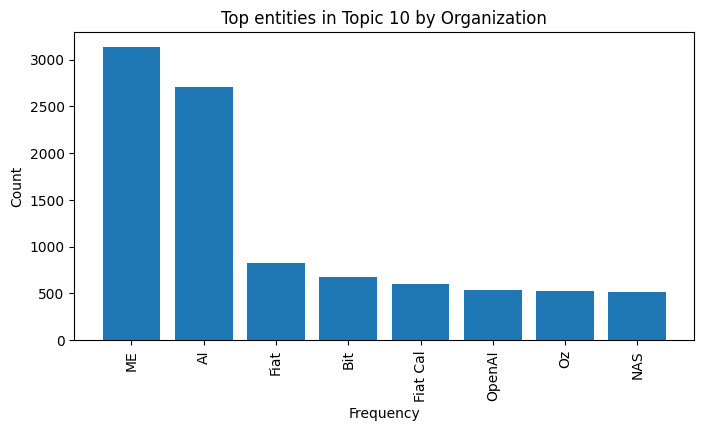

,word,entity,frenqency
575,AI,PRODUCT,142.0
1510,Strike,PRODUCT,88.0
638,Ai,PRODUCT,69.0
574,ACT,PRODUCT,66.0
1472,Sleepless AI,PRODUCT,62.0
683,Auto,PRODUCT,41.0
1291,OpenAI,PRODUCT,40.0
1091,Ko,PRODUCT,32.0


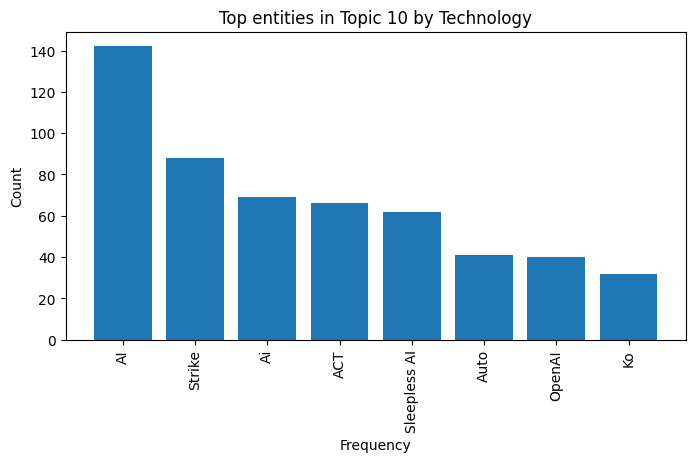

In [20]:
def calculate_entetis_by_product(topic, title):
  # Filter by topic
  df_aux = df_news_AI_entity[df_news_AI_entity['Topic_Number']==topic]

  # Do the explotion
  df_exploded = df_aux.explode(['word', 'entity', 'frenqency'])

  # 2. Ensure the frequency column is treated as numeric integers
  df_exploded['frenqency'] = pd.to_numeric(df_exploded['frenqency'])

  # 3. Group by 'word' and 'entity', sum the frequencies
  frenq_entities_bytopic = (df_exploded
                    .groupby(['word', 'entity'], as_index=False)['frenqency']
                    .sum()
                    .sort_values(by='frenqency', ascending=False))

  # 4. Reset the index for a clean output
  frenq_entities_bytopic = frenq_entities_bytopic.reset_index(drop=True)
  #total
  total = frenq_entities_bytopic['frenqency'].sum()
  frenq_entities_bytopic['percentage'] = frenq_entities_bytopic['frenqency'] / total * 100


  # remove noise tokens
  stop_tokens = ['##t','##xe','##3','Per','Cha','PR','##uters','##TC','##VI', '##less AI','So', '##8','##lot','Company','PA','Cry',
                 '##ripps News','Ex','##GP','##V','##s','##C','In','##ews', 'Pi','the','Co','NY','Sir','##U','##less' ]


  frenq_entities_bytopic = frenq_entities_bytopic[~frenq_entities_bytopic['word'].isin(stop_tokens)].copy()
  #for stop_token in stop_tokens:
  #  frenq_entities_bytopic = frenq_entities_bytopic[frenq_entities_bytopic['word']!=stop_token]

  # Replace some words
  frenq_entities_bytopic['word'] = frenq_entities_bytopic['word'].str.replace('##A', 'AI')
  frenq_entities_bytopic['word'] = frenq_entities_bytopic['word'].str.replace('##vidia','Nvidia')
  frenq_entities_bytopic['word'] = frenq_entities_bytopic['word'].str.replace('##VIDIA','Nvidia')
  frenq_entities_bytopic['word'] = frenq_entities_bytopic['word'].str.replace('Open','OpenAI')
  frenq_entities_bytopic['word'] = frenq_entities_bytopic['word'].str.replace('OpenAIAI','OpenAI')


  # Filter only product
  df_aux = frenq_entities_bytopic[frenq_entities_bytopic['entity']=='ORG']
  df_aux = df_aux.groupby(['word','entity'])['frenqency'].sum().reset_index()
  df_aux = df_aux.sort_values(by='frenqency', ascending=False)

  df_aux = df_aux.head(8)
  display(df_aux)

  plt.figure(figsize=(8, 4))
  plt.bar(df_aux['word'], df_aux['frenqency'])
  title_pro = title + ' Organization'
  plt.title(title_pro)
  plt.xlabel("Frequency")
  plt.ylabel("Count")
  plt.xticks(rotation=90)
  plt.show()


  # Filter only product
  df_aux = frenq_entities_bytopic[frenq_entities_bytopic['entity']=='PRODUCT']
  df_aux = df_aux.groupby(['word','entity'])['frenqency'].sum().reset_index()
  df_aux = df_aux.sort_values(by='frenqency', ascending=False)

  df_aux = df_aux.head(8)
  display(df_aux)

  plt.figure(figsize=(8, 4))
  plt.bar(df_aux['word'], df_aux['frenqency'])
  title_tec = title + ' Technology'
  plt.title(title_tec)
  plt.xlabel("Frequency")
  plt.ylabel("Count")
  plt.xticks(rotation=90)
  plt.show()

# Called the function
for topic in range(0,10):
  print('Topic:', topic+1)
  title = 'Top entities in Topic '+str(topic+1)+' by'
  calculate_entetis_by_product(topic, title)